In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')

import os, sys
import pandas as pd
from functools import reduce
from copy import deepcopy

from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit.Chem import AllChem, rdDepictor
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 700, 500
# IPythonConsole.drawOptions.addAtomIndices = True

def reset_view(mol):
    """ Reset coordinates for display """
    mol = deepcopy(mol)
    rdDepictor.SetPreferCoordGen(True)
    rdDepictor.Compute2DCoords(mol)
    rdDepictor.StraightenDepiction(mol)
    return mol

In [2]:
database3 = pd.read_csv('data/Database3.csv')
PandasTools.AddMoleculeColumnToFrame(database3, 'ISOSMILES')
df_lipidmaps = pd.read_pickle('data/Database_lipidmaps.pkl')

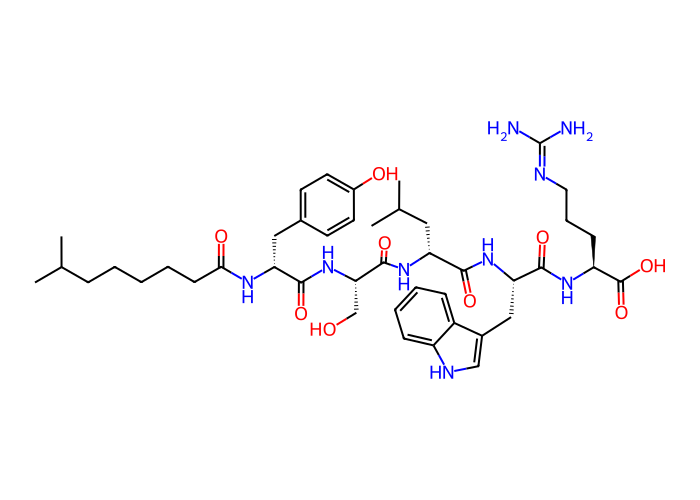

CytoscapeWidget(cytoscape_layout={'name': 'cose'}, cytoscape_style=[{'selector': 'node', 'css': {'content': 'd…

In [8]:
query_mol = database3.at[39, 'ROMol']
display(reset_view(query_mol))

from new_geass import Geass
geass = Geass()
final_prods = geass.get_fragments(query_mol)

final_Prod = reduce(Chem.CombineMols, final_prods)
geass.show_connections_graph()

In [ ]:
# from new_geass import reactions
# rxn = reactions['amide']
rxn = AllChem.ReactionFromSmarts("[NX3;$(N([#6])[#6]):0]-[C:1]=[O:2]>>[#7:0].[C:1](=[O:2])-O")  #<-- No parentheses!

frags = list(rxn.RunReactants([Chem.MolFromSmiles('CCCCCCCC(=O)NC(CC1=CC=C(C=C1)O)C(=O)O')])[0])
frags[1] = Chem.MolFromSmiles('CCCCCCCCCCCCCC(=O)O')

# Reversing reaction
rxn_rev = AllChem.ChemicalReaction()
for i in range(rxn.GetNumReactantTemplates()):
    rxn_rev.AddProductTemplate(rxn.GetReactantTemplate(i))
for i in range(rxn.GetNumProductTemplates()):
    rxn_rev.AddReactantTemplate(rxn.GetProductTemplate(i))
rxn_rev.Initialize()

new_prods = rxn_rev.RunReactants(frags)[0][0]
display(new_prods)

In [ ]:
# sys.path.append(R'C:\Users\Idener\Sync\CODE')
# from CADDTools import molecular_methods as MolMtd
# MolMtd.smartsview('[C;$(C(=O)C)]')

In [ ]:
old_tail = 'CCCCCCCCCCCCCC(=O)O'
old_tail = Chem.ReplaceSubstructs(Chem.MolFromSmiles(old_tail),
                                  Chem.MolFromSmiles('C(=O)O'),
                                  Chem.MolFromSmiles('C=O'),
                                  replaceAll=True)[0]

# Renumber old tail atoms (atom 0 must be the one involved in bond breaking)
acetyl_patt = old_tail.GetSubstructMatch(Chem.MolFromSmarts('[C;$(C(=O)C)]'))
new_order_patt = list(acetyl_patt) + [x for x in range(old_tail.GetNumAtoms()) if x not in acetyl_patt][::-1]
old_tail = AllChem.RenumberAtoms(old_tail, new_order_patt)
old_tail

In [ ]:
new_tails = df_lipidmaps[df_lipidmaps['ID'].str.contains('FA01')]['ISOSMILES'].head(5).tolist()

chimeras = []
for new_tail in new_tails:
    # Skip if pattern and replacement are the same
    if new_tail == old_tail:
        continue

    new_tail = Chem.MolFromSmiles(new_tail)
    
    # Get carboxyl carbon index
    C_idx = new_tail.GetSubstructMatch(Chem.MolFromSmarts('[C;$(C(=O)[OX2H1])]'))[0]

    # Replace tails in query molecule
    chimera = AllChem.ReplaceSubstructs(query_mol, old_tail, new_tail,
                                        replacementConnectionPoint=C_idx)[0]
    # Remove condensed-out -OH
    chimera = Chem.ReplaceSubstructs(chimera,
                                     Chem.MolFromSmarts('C[O;$(OC(=O)(*)(*))]'),
                                     Chem.MolFromSmiles('C'))[0]
    chimeras.append(reset_view(chimera))
display(query_mol, *chimeras)

In [7]:
# df_chimeras = pd.DataFrame({'ISOSMILES': [Chem.MolToSmiles(x) for x in chimeras]})
# df_chimeras.to_csv(f"{workdir}/DeliverableMarta/chimeras.csv", index=False)